## Initialization

#### Import Library, find available devices

In [1]:
# Initialization code for 3.3 V SiGe LVR Load Regulation Testing.
# This block identifies and initializes the connected SMUs (Source Measure Units).
# If running for the first time, ensure the SMU names are correctly referenced in the subsequent code block.

# This program sweeps VIN for a fixed VREF and measures total quiescent current (IQ) and VOUT. 
# This program sets up a directory for all measurements taken at a specific temperature by prompting the user for the temperature.
# This program creates a .csv file to save the measurements for a VREF in the temperature directory. 

# The setup assumes the use of two SMUs:
# - One dedicated to VIN sweeps.
# - One Sinks a load current and measures VOUT.
import pyvisa                    # Importing the pyvisa library for instrument communication
import time                      # Importing the time module to handle time-related tasks (e.g., delays)
import matplotlib.pyplot as plt  # Importing matplotlib.pyplot for plotting graphs and visualizing data
import numpy as np               # Importing numpy for numerical operations, particularly with arrays
import pandas as pd              # Importing pandas as pd for data manipulation and analysis
import os                        # Importing os to interact with the operating system, such as handling file paths
import csv                       # Importing csv to read from and write to CSV files
from IPython.display import display, clear_output
from datetime import date           # Importing date to read current date
from collections import defaultdict

In [55]:
# Loads ICASL.py from a higher directory
# This file contains functions written by us that can be called with "ICASL.example_function_name"
import importlib.util    # Used to load python files more dynamically (ICASL.py)
quiet=True
current_dir = "."
target_file = "ICASL.py"
target_name = "ICASL"
while True:
    if not quiet: print(current_dir)
    # Check if ICASL is in the current directory
    ICASL_path = os.path.join(current_dir, target_file)
    if not quiet: print(ICASL_path)
    if os.path.isfile(ICASL_path):
        # Loads ICASL.py
        spec = importlib.util.spec_from_file_location(target_name, ICASL_path)
        ICASL = importlib.util.module_from_spec(spec)
        spec.loader.exec_module(ICASL)
        break
    else:
        # Move one level up
        parent_dir = os.path.join(current_dir, "..")
        if not quiet: print(parent_dir)
        if current_dir == parent_dir:  # Reached the root directory
            raise ValueError("ICASL.py not found")
        else:
            current_dir = parent_dir
ICASL.test()

ICASL is loaded!


In [20]:
# Data extracted from your HKJ image
#soc_points = np.array([1.0, 0.8, 0.7, 0.6, 0.5, 0.4, 0.3, 0.2, 0.1, 0.0])
#ocv_points = np.array([1.43, 1.36, 1.29, 1.25, 1.22, 1.21, 1.2, 1.18, 1.156, 1.1])
soc_points = np.array([1.0, 0.7, 0.6, 0.5, 0.4, 0.3, 0.2, 0.1, 0.0])
ocv_points = np.array([1.43, 1.29, 1.25, 1.22, 1.21, 1.2, 1.18, 1.156, 1.12])

z = np.polyfit(soc_points, ocv_points, 5)
p = np.poly1d(z)

class BatteryEKF:
    def __init__(self, soc_lut, r0_lut, r1_lut, c1_lut, r2_lut, c2_lut, Capacity):
        self.soc_lut = soc_lut
        self.r0_lut = r0_lut
        self.r1_lut = r1_lut
        self.c1_lut = c1_lut
        self.r2_lut = r2_lut
        self.c2_lut = c2_lut
        self.Q_cap = Capacity * 3600 # Ah to Ampere-seconds
        
        # State: [SOC, Vc1, Vc2]
        self.x = np.array([[1.0], [0.0], [0.0]]) 
        self.P = np.eye(3) * .001
        
        # Process noise usually scales with time, but keeping it simple for now
        self.Q = np.diag([1e-4, 1e-5, 1e-5]) 
        self.R = 1e-6

    def initialize_soc(self, measured_voltage, soc_points, ocv_points):
        """
        Call this ONCE before starting the loop to find a starting SOC.
        """
        # Use linear interpolation to find SOC from Voltage
        # Note: interp expects the x-coordinates (ocv) to be increasing
        initial_soc = np.interp(measured_voltage, ocv_points[::-1], soc_points[::-1])
        
        # Update the state vector
        self.x[0, 0] = initial_soc
        return initial_soc
    def get_parameters(self):
        current_soc = np.clip(self.x[0, 0], 0, 1)
        
        # Interpolate each parameter based on current SOC
        r0 = np.interp(current_soc, self.soc_lut, self.r0_lut)
        r1 = np.interp(current_soc, self.soc_lut, self.r1_lut)
        c1 = np.interp(current_soc, self.soc_lut, self.c1_lut)
        r2 = np.interp(current_soc, self.soc_lut, self.r2_lut)
        c2 = np.interp(current_soc, self.soc_lut, self.c2_lut)
        
        return r0, r1, c1, r2, c2
    def get_OCV(self, soc):
        # Ensure SOC stays in bounds [0, 1]
        soc = np.clip(soc, 0, 1)
        return p(soc)

    # Derivative for the EKF Jacobian (H matrix)
    def get_dOCV_dSOC(self, soc):
        p_derivative = np.polyder(p)
        return p_derivative(soc)

    def predict(self, current, dt):
        # Fetch dynamic parameters for the current SOC
        r0, r1, c1, r2, c2 = self.get_parameters()
        
        exp1 = np.exp(-dt / (r1 * c1))
        exp2 = np.exp(-dt / (r2 * c2))
        
        A = np.array([[1, 0, 0], [0, exp1, 0], [0, 0, exp2]])
        B = np.array([[-dt / self.Q_cap], [r1 * (1 - exp1)], [r2 * (1 - exp2)]])
        
        self.x = A @ self.x + B * current
        self.P = A @ self.P @ A.T + (self.Q * dt)

    def update(self, measured_voltage, current):
        # 2. Observation (h)
        # Vt = OCV(SOC) - I*R0 - Vc1 - Vc2
        r0, r1, c1, r2, c2 = self.get_parameters()
        soc_val = self.x[0, 0]
        v_predicted = self.get_OCV(soc_val) - current * r0 - self.x[1, 0] - self.x[2, 0]
        
        # 3. Jacobian (H) - Derivative of h with respect to x
        H = np.array([[max(self.get_dOCV_dSOC(soc_val), 0.01), -1, -1]])
        
        # 4. Kalman Gain
        S = H @ self.P @ H.T + self.R
        K = self.P @ H.T @ np.linalg.inv(S)
        
        # 5. Update State and Covariance
        innovation = measured_voltage - v_predicted
        self.x = self.x + K * innovation
        self.P = (np.eye(3) - K @ H) @ self.P
        
        return self.x[0, 0] # Return estimated SOC

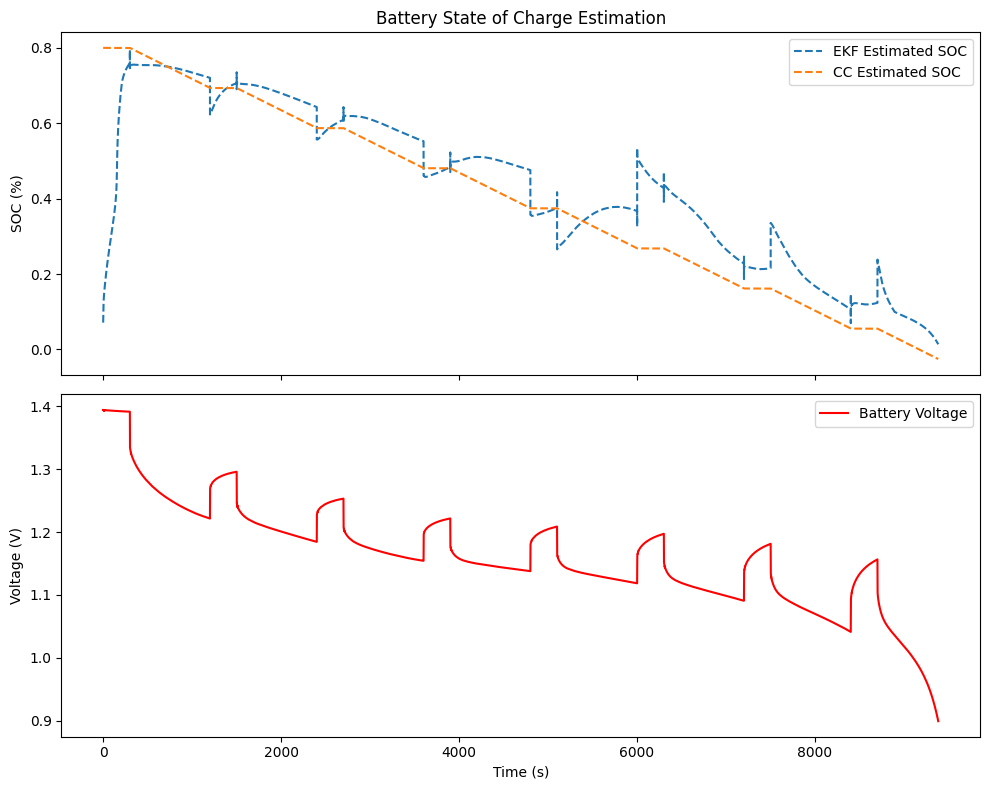

In [21]:
df = pd.read_csv("Test_1/complete.csv")

soc_points = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 1.0]

r0_values = [0.05, 0.05, 0.05, 0.05, 0.05, 0.05, 0.05, 0.05, 0.05]
#r0_values = [0.03, 0.03, 0.03, 0.03, 0.03, 0.03, 0.03, 0.03, 0.03]
r1_values = [0.11, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.03]
c1_values = [151, 349, 497, 575, 677, 744, 569, 328, 4196]
r2_values = [0.11, 0.06, 0.04, 0.03, 0.03, 0.02, 0.02, 0.02, 0.03]
c2_values = [2270, 2145, 3212, 4128, 4963, 5374, 5026, 4342, 49593]




ekf = BatteryEKF(soc_points, r0_values, r1_values, c1_values, r2_values, c2_values, 2.5)
estimated_soc = []
CC_soc = []
init_soc =.8
capacity = 2.35
v_start = df['voltage'][0]
ekf.initialize_soc(v_start, soc_points, ocv_points)

for i in range(len(df)):
    # Calculate dt dynamically
    if i == 0:
        dt = 0.1 # Small default for first step
        DOD = [0]
    else:
        dt = df["times"][i] - df["times"][i-1]
        DOD.append(DOD[-1]+(df["current"][i]*(dt)/3600))
    CC_soc.append(init_soc+DOD[i]/(capacity))
    # Only run predict/update if dt is valid (prevents errors from duplicate timestamps)
    if dt > 0:
        ekf.predict(-df["current"][i], dt)
        soc = ekf.update(df["voltage"][i], -df["current"][i])
        estimated_soc.append(soc)
    else:
        estimated_soc.append(estimated_soc[-1]) # Keep last value

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

# Plot 1: SOC (Top)
ax1.plot(df["times"], estimated_soc, '--', label='EKF Estimated SOC')
ax1.plot(df["times"], CC_soc, '--', label='CC Estimated SOC')
ax1.set_ylabel('SOC (%)')
ax1.legend()
ax1.set_title('Battery State of Charge Estimation')

# Plot 2: Voltage (Bottom)
ax2.plot(df["times"], df['voltage'], 'r-', label='Battery Voltage') # Changed color to red for clarity
ax2.set_ylabel('Voltage (V)')
ax2.set_xlabel('Time (s)')
ax2.legend()

plt.tight_layout() # Prevents labels from overlapping
plt.show()